# Phase 6 — Part 2 of 3: GPU monitor preconditioning
**Inputs:** Part 1 SEG-Y checkpoints. This notebook reconstructs original variable names using disk-backed float32 arrays and runs the existing tiled **Cell 16A**. It then exports a preconditioned monitor SEG-Y. Rerun only if filter settings or Part 1 input change. The output SEG-Y is separate from the raw matched monitor. Cache validity should be checked before reusing a previous filtered result.

In [1]:

# Reusable Phase 6 SEG-Y checkpoint I/O: writes IEEE float32 with baseline headers.
import numpy as np, pandas as pd, segyio, json
from pathlib import Path
CHECKPOINT_ROOT=Path('/home/apgce_team_08/Phase6_Checkpoints')
CHECKPOINT_ROOT.mkdir(parents=True,exist_ok=True)
def export_segy(path, data, geometry, reference_path, reference_indices=None, batch=128):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    geometry=geometry.reset_index(drop=True)
    if data.shape[0]!=len(geometry):raise ValueError('Trace geometry mismatch')
    if not np.isfinite(geometry[['X','Y']].to_numpy()).all():
        raise ValueError('Invalid X/Y; cannot write reliable SEG-Y geometry')
    tmp=path.with_suffix('.partial.sgy')
    if tmp.exists():tmp.unlink()
    with segyio.open(str(reference_path),'r',ignore_geometry=True) as src:
        if reference_indices is None:
            if src.tracecount!=len(geometry):raise ValueError('Reference trace count differs')
            reference_indices=np.arange(len(geometry))
        if len(src.samples)!=data.shape[1]:raise ValueError('Reference sample axis differs')
        spec=segyio.spec(); spec.tracecount=len(geometry)
        spec.samples=src.samples; spec.format=5
        with segyio.create(str(tmp),spec) as dst:
            dst.bin=src.bin; dst.bin[segyio.BinField.Format]=5
            dst.text[0]=src.text[0]
            for i in range(len(geometry)):
                header=dict(src.header[int(reference_indices[i])]); g=geometry.iloc[i]
                header[segyio.TraceField.INLINE_3D]=int(g.Inline)
                header[segyio.TraceField.CROSSLINE_3D]=int(g.Crossline)
                scalar=int(header.get(segyio.TraceField.SourceGroupScalar,1))
                if scalar==0:scalar=1;header[segyio.TraceField.SourceGroupScalar]=1
                factor=scalar if scalar>0 else 1/abs(scalar)
                header[segyio.TraceField.CDP_X]=int(round(float(g.X)/factor))
                header[segyio.TraceField.CDP_Y]=int(round(float(g.Y)/factor))
                dst.header[i]=header
                dst.trace[i]=np.asarray(data[i],dtype=np.float32)
                if (i+1)%100000==0:print(path.name,i+1,'/',len(geometry))
            dst.flush()
    with segyio.open(str(tmp),'r',ignore_geometry=True) as check:
        if check.tracecount!=len(geometry) or len(check.samples)!=data.shape[1]:
            raise RuntimeError('Written SEG-Y dimensions failed QC')
        if check.bin[segyio.BinField.Format]!=5:raise RuntimeError('Output not IEEE float32')
        test=np.unique(np.linspace(0,len(geometry)-1,min(20,len(geometry)),dtype=int))
        for i in test:
            h=check.header[int(i)]
            if (int(h[segyio.TraceField.INLINE_3D])!=int(geometry.iloc[i].Inline) or
                int(h[segyio.TraceField.CROSSLINE_3D])!=int(geometry.iloc[i].Crossline)):
                raise RuntimeError('SEG-Y trace-order QC failed')
            scalar=int(h[segyio.TraceField.SourceGroupScalar]);factor=scalar if scalar>0 else (1/abs(scalar) if scalar<0 else 1)
            if abs(h[segyio.TraceField.CDP_X]*factor-float(geometry.iloc[i].X))>max(.01,abs(factor)/2+.01):
                raise RuntimeError('SEG-Y X coordinate QC failed')
    tmp.replace(path)
    print('Verified:',path)

def load_checkpoint(path,cache_dir):
    path=Path(path);cache_dir=Path(cache_dir);cache_dir.mkdir(parents=True,exist_ok=True)
    if not path.exists():raise FileNotFoundError(f'Missing checkpoint: {path}; run previous stage')
    with segyio.open(str(path),'r',ignore_geometry=True) as f:
        n,ns=f.tracecount,len(f.samples);samples=np.asarray(f.samples,dtype=np.float64)
        dt=float(f.bin[segyio.BinField.Interval])/1000
        il=np.asarray(f.attributes(segyio.TraceField.INLINE_3D)[:],dtype=np.int32)
        xl=np.asarray(f.attributes(segyio.TraceField.CROSSLINE_3D)[:],dtype=np.int32)
        xr=np.asarray(f.attributes(segyio.TraceField.CDP_X)[:],dtype=np.float64)
        yr=np.asarray(f.attributes(segyio.TraceField.CDP_Y)[:],dtype=np.float64)
        scalar=np.asarray(f.attributes(segyio.TraceField.SourceGroupScalar)[:],dtype=np.int32)
        scale=np.where(scalar>0,scalar,np.where(scalar<0,1/np.maximum(np.abs(scalar),1),1))
        geo=pd.DataFrame({'Inline':il,'Crossline':xl,'X':xr*scale,'Y':yr*scale,
                          'Trace_Index':np.arange(n,dtype=np.int64)})
        if geo.duplicated(['Inline','Crossline']).any():raise ValueError('Duplicate bins in '+str(path))
        binary=cache_dir/(path.stem+'.float32.dat')
        meta=cache_dir/(path.stem+'.json')
        signature={'source':str(path.resolve()),'size':path.stat().st_size,
                   'mtime_ns':path.stat().st_mtime_ns,'shape':[n,ns]}
        ready=binary.exists() and binary.stat().st_size==n*ns*4 and meta.exists()
        if ready:
            try:ready=json.loads(meta.read_text())==signature
            except Exception:ready=False
        if not ready:
            temp=binary.with_suffix('.partial.dat')
            if temp.exists():temp.unlink()
            arr=np.memmap(temp,dtype='float32',mode='w+',shape=(n,ns))
            for i in range(n):
                arr[i]=np.asarray(f.trace[i],dtype=np.float32)
                if (i+1)%100000==0:print('Caching',path.name,i+1,'/',n)
            arr.flush();del arr;temp.replace(binary);meta.write_text(json.dumps(signature,indent=2))
        arr=np.memmap(binary,dtype='float32',mode='r',shape=(n,ns))
    print('Loaded disk-backed',path.name,arr.shape)
    return arr,geo,samples,dt

def validate_pair(a,ag,at,b,bg,bt):
    if a.shape!=b.shape or not np.array_equal(at,bt):raise ValueError('Volume/time mismatch')
    for key in ('Inline','Crossline'):
        if not np.array_equal(ag[key].to_numpy(),bg[key].to_numpy()):
            raise ValueError('Trace order mismatch in '+key)
    if not np.allclose(ag[['X','Y']],bg[['X','Y']],rtol=0,atol=.1,equal_nan=True):
        raise ValueError('XY mismatch across SEG-Y checkpoints')


In [2]:

# PART 2 INPUTS — no original SEG-Y matching cells required
monitor_matched,matched_geometry,monitor_samples,monitor_dt=load_checkpoint(
    CHECKPOINT_ROOT/'Monitor_Matched.sgy',CHECKPOINT_ROOT/'part2_input_cache')
# Existing Cell 16A only needs monitor_matched, matched_geometry and monitor_samples.
REBUILD_PRECONDITIONING=True
print('Part 2 input ready. Run next cell: GPU preconditioning.')


Loaded disk-backed Monitor_Matched.sgy (1240941, 1301)
Part 2 input ready. Run next cell: GPU preconditioning.


Reusing previously conditioned GPU volume: /home/apgce_team_08/Autopick_Horizon/Preconditioning/Monitor_Picking_GPU_Highcut_VG2Pass.float32.dat
GPU conditioned picking volume ready: /home/apgce_team_08/Autopick_Horizon/Preconditioning/Monitor_Picking_GPU_Highcut_VG2Pass.float32.dat
Original monitor_matched remains unchanged.


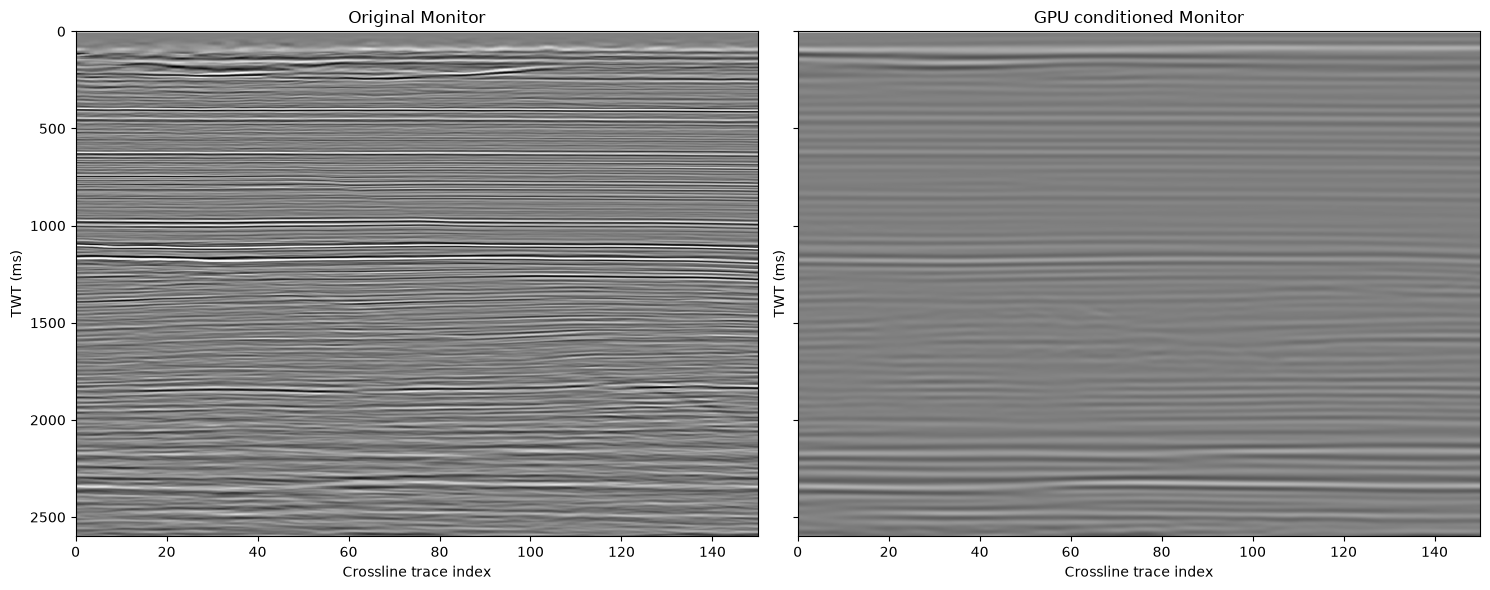

Cell 16A completed: tiled, disk-backed GPU monitor preconditioning.


In [3]:
# CELL 16A — GPU MONITOR PRECONDITIONING (CuPy / CUDA)
# High-cut 24–30 Hz with cosine taper, followed by TWO dip-steered 2D passes:
#   (1) Crossline direction in constant-Inline sections
#   (2) Inline direction in constant-Crossline sections
# This is a Van Gogh-LIKE structure-oriented smoother, not a proprietary implementation.
# Original monitor_matched and baseline_matched are NEVER modified.
# EDIT FILTER PARAMETERS BELOW; set REBUILD_PRECONDITIONING=True after any input change.
from pathlib import Path
import gc, json, hashlib
import numpy as np
import pandas as pd
import cupy as cp
from cupyx.scipy.ndimage import gaussian_filter as gpu_gaussian_filter
from cupyx.scipy.ndimage import map_coordinates as gpu_map_coordinates
import matplotlib.pyplot as plt

ENABLE_HIGHCUT = True
HIGHCUT_PASS_HZ = 24.0       # EDIT: 100% pass below 24 Hz
HIGHCUT_STOP_HZ = 30.0       # EDIT: zero amplitude at >=30 Hz
ENABLE_VANGOGH = True
VG_PASS_DIRECTIONS = ('crossline', 'inline')  # EDIT: pass order; use tuple() to disable
VG_SPATIAL_RADIUS_TRACES = 15   # EDIT: +/- neighbouring traces
VG_TENSOR_SIGMA_X = 15.0        # EDIT: tensor smoothing along spatial direction, bins
VG_TENSOR_SIGMA_T = 15.0        # EDIT: tensor smoothing in time samples
VG_MAX_DIP_SAMPLES_PER_TRACE = 3.0
VG_MIN_COHERENCE = 0.20
VG_BLEND = 0.85                # EDIT: 0=no smoothing; 1=full dip-steered average
VG_ITERATIONS = 1             # EDIT: iterations PER directional pass
GPU_FFT_BATCH_TRACES = 128    # EDIT: reduce if CUDA out-of-memory
REBUILD_PRECONDITIONING = False  # EDIT: False only when you KNOW source data unchanged
OUTPUT_DIR_PRE = Path('/home/apgce_team_08/Autopick_Horizon/Preconditioning')
SHOW_PRECONDITIONING_QC = True
QC_MAX_CROSSLINES = 150
VG_CORE_TRACES = 48  # spatial tiling; lower to 24 if needed
VG_TIME_SAMPLES = 256  # time tiling; lower to 128 if needed
GPU_MEMORY_LIMIT_FRACTION = 0.60

for name in ('monitor_matched','matched_geometry','monitor_samples'):
    if name not in globals(): raise NameError(f'Missing {name}; run seismic matching cells first')
if cp.cuda.runtime.getDeviceCount() < 1: raise RuntimeError('No CUDA GPU visible in this SLURM kernel')
source = monitor_matched
ntr, ns = source.shape
geom_pre = matched_geometry.reset_index(drop=True)
if len(geom_pre) != ntr: raise ValueError('Geometry and trace count differ')
if not {'Inline','Crossline'}.issubset(geom_pre.columns): raise ValueError('Inline/Crossline missing')
taxis_pre = np.asarray(monitor_samples, dtype=np.float64)
dt_ms_pre = float(np.median(np.diff(taxis_pre)))
if dt_ms_pre <= 0 or not np.allclose(np.diff(taxis_pre),dt_ms_pre,atol=1e-3):
    raise ValueError('Expected uniform increasing time samples in ms')
nyquist = 500.0 / dt_ms_pre
if ENABLE_HIGHCUT and not (0 < HIGHCUT_PASS_HZ < HIGHCUT_STOP_HZ <= nyquist):
    raise ValueError(f'Invalid high-cut corners; Nyquist is {nyquist:g} Hz')
if not (0 <= VG_BLEND <= 1 and 0 <= VG_MIN_COHERENCE <= 1): raise ValueError('Invalid VG parameters')
if VG_ITERATIONS < 1 or VG_SPATIAL_RADIUS_TRACES < 1: raise ValueError('VG iteration/radius must be >=1')
if any(d not in ('crossline','inline') for d in VG_PASS_DIRECTIONS): raise ValueError('Unknown VG direction')
OUTPUT_DIR_PRE.mkdir(parents=True,exist_ok=True)
output_path = OUTPUT_DIR_PRE/'Monitor_Picking_GPU_Highcut_VG2Pass.float32.dat'
metadata_path = output_path.with_suffix(output_path.suffix+'.json')
settings_pre = dict(algorithm_version='phase6_tiled_v2',shape=[int(ntr),int(ns)],dt_ms=dt_ms_pre,
    highcut=ENABLE_HIGHCUT,pass_hz=HIGHCUT_PASS_HZ,stop_hz=HIGHCUT_STOP_HZ,
    vg=ENABLE_VANGOGH,directions=list(VG_PASS_DIRECTIONS),radius=VG_SPATIAL_RADIUS_TRACES,
    tensor_x=VG_TENSOR_SIGMA_X,tensor_t=VG_TENSOR_SIGMA_T,max_dip=VG_MAX_DIP_SAMPLES_PER_TRACE,
    coherence=VG_MIN_COHERENCE,blend=VG_BLEND,iterations=VG_ITERATIONS,
    geometry_fingerprint=hashlib.sha256(np.asarray(geom_pre[['Inline','Crossline']],dtype=np.int64).tobytes()).hexdigest())
reuse_pre = False
if not REBUILD_PRECONDITIONING and output_path.exists() and metadata_path.exists():
    reuse_pre = (json.loads(metadata_path.read_text()) == settings_pre and
                 output_path.stat().st_size == ntr*ns*4)

# GPU FFT on one batch; CPU interpolation is limited to traces containing NaNs.
# Invalid samples are restored to NaN after filtering.
def gpu_highcut_batch(batch, frequency_response, pad):
    a = np.asarray(batch,dtype=np.float32).copy()
    mask = np.isfinite(a)
    good = mask.sum(axis=1)>=3
    out = np.full_like(a,np.nan)
    if not np.any(good): return out
    a=a[good]; valid=mask[good]
    t=np.arange(ns)
    for row in np.flatnonzero(~valid.all(axis=1)):
        ok=t[valid[row]]
        a[row,~valid[row]]=np.interp(t[~valid[row]],ok,a[row,ok])
    gpu=cp.asarray(a)
    padded=cp.pad(gpu,((0,0),(pad,pad)),mode='reflect')
    spectrum=cp.fft.rfft(padded,axis=1)
    spectrum*=frequency_response[None,:]
    filtered=cp.fft.irfft(spectrum,n=padded.shape[1],axis=1)[:,pad:pad+ns]
    result=cp.asnumpy(filtered.astype(cp.float32))
    result[~valid]=np.nan
    out[good]=result
    del gpu,padded,spectrum,filtered
    return out

# Section shape [spatial bin, time]. Work only on consecutive actual bin numbers.
# All dip estimation, spatial sampling and smoothing below run on the GPU.
def gpu_vg_section(section):
    if section.shape[0]<3: return np.asarray(section,dtype=np.float32)
    original=cp.asarray(np.asarray(section,dtype=np.float32))
    original_valid=cp.isfinite(original)
    if not bool(cp.any(original_valid)): return np.asarray(section,dtype=np.float32)
    work=original.copy()
    nr,nt=work.shape
    row=cp.arange(nr,dtype=cp.float32)[:,None]
    col=cp.arange(nt,dtype=cp.float32)[None,:]
    for iteration in range(VG_ITERATIONS):
        valid=cp.isfinite(work)
        filled=cp.where(valid,work,0.).astype(cp.float32)
        weight=gpu_gaussian_filter(valid.astype(cp.float32),(VG_TENSOR_SIGMA_X,VG_TENSOR_SIGMA_T),mode='nearest')
        sm=gpu_gaussian_filter(filled,(VG_TENSOR_SIGMA_X,VG_TENSOR_SIGMA_T),mode='nearest')/cp.maximum(weight,1e-5)
        gx,gt=cp.gradient(sm)
        jxx=gpu_gaussian_filter(gx*gx,(VG_TENSOR_SIGMA_X,VG_TENSOR_SIGMA_T),mode='nearest')
        jtt=gpu_gaussian_filter(gt*gt,(VG_TENSOR_SIGMA_X,VG_TENSOR_SIGMA_T),mode='nearest')
        jxt=gpu_gaussian_filter(gx*gt,(VG_TENSOR_SIGMA_X,VG_TENSOR_SIGMA_T),mode='nearest')
        eps=cp.maximum(cp.max(jtt+jxx)*1e-7,cp.float32(1e-10))
        slope=cp.clip(-jxt/(jtt+eps),-VG_MAX_DIP_SAMPLES_PER_TRACE,VG_MAX_DIP_SAMPLES_PER_TRACE)
        coherence=cp.clip(cp.sqrt((jxx-jtt)**2+4*jxt*jxt)/(jxx+jtt+eps),0,1)
        weighted=filled.copy(); total=valid.astype(cp.float32)
        for dx in range(-VG_SPATIAL_RADIUS_TRACES,VG_SPATIAL_RADIUS_TRACES+1):
            if dx==0: continue
            w=float(np.exp(-.5*(dx/max(1,VG_SPATIAL_RADIUS_TRACES/1.5))**2))
            # Two coordinate planes still allocated, but only for a small spatial/time tile.
            coords=cp.stack(cp.broadcast_arrays(row+dx,col+dx*slope),axis=0)
            sample=gpu_map_coordinates(filled,coords,order=1,mode='constant',cval=0.)
            support=gpu_map_coordinates(valid.astype(cp.float32),coords,order=1,mode='constant',cval=0.)
            weighted+=w*sample
            total+=w*support
        steered=weighted/cp.maximum(total,1e-5)
        strength=VG_BLEND*cp.clip((coherence-VG_MIN_COHERENCE)/max(1e-6,1-VG_MIN_COHERENCE),0,1)
        work=cp.where(original_valid,((1-strength)*filled+strength*steered),cp.nan).astype(cp.float32)
    return cp.asnumpy(work)

def gpu_vg_section_tiled(section):
    """Overlap-save GPU filtering: bounded memory per tile, original sample alignment."""
    section=np.asarray(section,dtype=np.float32)
    nr,nt=section.shape
    result=np.empty_like(section)
    # Gaussian filters need several sigma of halo; dip steering needs radius*max_dip.
    halo_x=max(16,int(np.ceil(4*VG_TENSOR_SIGMA_X))+VG_SPATIAL_RADIUS_TRACES+2)
    halo_t=max(24,int(np.ceil(4*VG_TENSOR_SIGMA_T))+int(np.ceil(VG_SPATIAL_RADIUS_TRACES*VG_MAX_DIP_SAMPLES_PER_TRACE))+4)
    for r0 in range(0,nr,VG_CORE_TRACES):
        r1=min(nr,r0+VG_CORE_TRACES)
        a=max(0,r0-halo_x);b=min(nr,r1+halo_x)
        for t0 in range(0,nt,VG_TIME_SAMPLES):
            t1=min(nt,t0+VG_TIME_SAMPLES)
            u=max(0,t0-halo_t);v=min(nt,t1+halo_t)
            tile=gpu_vg_section(section[a:b,u:v])
            result[r0:r1,t0:t1]=tile[r0-a:r1-a,t0-u:t1-u]
            del tile
        cp.get_default_memory_pool().free_all_blocks()
    return result

def directional_gpu_pass(input_path,output_path,direction):
    input_mm=np.memmap(input_path,dtype='float32',mode='r',shape=(ntr,ns))
    output_mm=np.memmap(output_path,dtype='float32',mode='w+',shape=(ntr,ns))
    # Initialize output with input to preserve all short runs and missing bins.
    for start in range(0,ntr,8192): output_mm[start:start+8192]=input_mm[start:start+8192]
    group='Inline' if direction=='crossline' else 'Crossline'
    along='Crossline' if direction=='crossline' else 'Inline'
    groups=geom_pre.groupby(group,sort=False).indices
    for ii,(_,ids) in enumerate(groups.items()):
        ids=np.asarray(ids,dtype=np.int64)
        ids=ids[np.argsort(geom_pre[along].to_numpy()[ids],kind='stable')]
        coords=geom_pre[along].to_numpy()[ids]
        splits=np.r_[0,np.flatnonzero(np.diff(coords)!=1)+1,len(ids)]
        for a,b in zip(splits[:-1],splits[1:]):
            run=ids[a:b]
            if len(run)>=3:
                # Do not upload an entire inline/crossline section to GPU.
                output_mm[run]=gpu_vg_section_tiled(input_mm[run])
        if (ii+1)%100==0: print(f'GPU VG {direction}: {ii+1:,}/{len(groups):,} sections')
    output_mm.flush()
    del output_mm,input_mm
    gc.collect()

if not reuse_pre:
    free_bytes,total_bytes=cp.cuda.runtime.memGetInfo()
    print(f"GPU available {free_bytes/2**30:.1f} GiB / {total_bytes/2**30:.1f} GiB; "
          f"VG tile core {VG_CORE_TRACES}x{VG_TIME_SAMPLES}")
    print(f'GPU preconditioning {ntr:,} traces × {ns:,} samples; GPU: {cp.cuda.runtime.getDeviceProperties(0)["name"]}')
    scratch=[]
    try:
        stage0=OUTPUT_DIR_PRE/'_gpu_highcut_stage.float32.dat'
        scratch.append(stage0)
        mm=np.memmap(stage0,dtype='float32',mode='w+',shape=(ntr,ns))
        pad=min(max(16,ns//10),256)
        freq=cp.fft.rfftfreq(ns+2*pad,d=dt_ms_pre/1000.)
        response=cp.ones_like(freq,dtype=cp.float32)
        if ENABLE_HIGHCUT:
            response=cp.where(freq>=HIGHCUT_STOP_HZ,0.,response)
            taper=(freq>HIGHCUT_PASS_HZ)&(freq<HIGHCUT_STOP_HZ)
            cosine=0.5*(1+cp.cos(cp.pi*(freq-HIGHCUT_PASS_HZ)/(HIGHCUT_STOP_HZ-HIGHCUT_PASS_HZ)))
            response=cp.where(taper,cosine,response).astype(cp.float32)
        for start in range(0,ntr,GPU_FFT_BATCH_TRACES):
            stop=min(start+GPU_FFT_BATCH_TRACES,ntr)
            if ENABLE_HIGHCUT: mm[start:stop]=gpu_highcut_batch(source[start:stop],response,pad)
            else: mm[start:stop]=np.asarray(source[start:stop],dtype=np.float32)
            if start//GPU_FFT_BATCH_TRACES%200==0: print(f'GPU high-cut: {stop:,}/{ntr:,}')
        mm.flush(); del mm; gc.collect()
        previous=stage0
        directions=VG_PASS_DIRECTIONS if ENABLE_VANGOGH else ()
        for pass_number,direction in enumerate(directions,1):
            target=OUTPUT_DIR_PRE/f'_gpu_vg_pass_{pass_number}.float32.dat'
            scratch.append(target)
            directional_gpu_pass(previous,target,direction)
            previous=target
        # Copy final scratch file to stable output without altering original seismic.
        # Replace atomically only after all stages complete.
        temp_final=OUTPUT_DIR_PRE/'_gpu_preconditioned_final.tmp'
        scratch.append(temp_final)
        import shutil
        shutil.copyfile(previous,temp_final)
        temp_final.replace(output_path)
        metadata_path.write_text(json.dumps(settings_pre,indent=2))
    finally:
        gc.collect()
        cp.get_default_memory_pool().free_all_blocks()
        for f in scratch:
            if f.exists():
                try: f.unlink()
                except OSError as exc: print(f'WARNING: Scratch cleanup failed: {f}: {exc}')
else:
    print('Reusing previously conditioned GPU volume:',output_path)
monitor_picking=np.memmap(output_path,dtype='float32',mode='r',shape=(ntr,ns))
print('GPU conditioned picking volume ready:',output_path)
print('Original monitor_matched remains unchanged.')
if SHOW_PRECONDITIONING_QC:
    selected_il=geom_pre['Inline'].value_counts().index[0]
    ids=np.flatnonzero(geom_pre['Inline'].to_numpy()==selected_il)
    ids=ids[np.argsort(geom_pre['Crossline'].to_numpy()[ids])]
    if len(ids)>QC_MAX_CROSSLINES:
        center=len(ids)//2; half=QC_MAX_CROSSLINES//2
        ids=ids[center-half:center-half+QC_MAX_CROSSLINES]
    if len(ids)>1:
        raw=np.asarray(source[ids],dtype=np.float32).T
        filtered=np.asarray(monitor_picking[ids],dtype=np.float32).T
        clip=np.nanpercentile(np.abs(raw),99)
        fig,ax=plt.subplots(1,2,figsize=(15,6),sharey=True)
        ax[0].imshow(raw,aspect='auto',cmap='gray',vmin=-clip,vmax=clip,extent=[0,len(ids),taxis_pre[-1],taxis_pre[0]])
        ax[1].imshow(filtered,aspect='auto',cmap='gray',vmin=-clip,vmax=clip,extent=[0,len(ids),taxis_pre[-1],taxis_pre[0]])
        ax[0].set_title('Original Monitor'); ax[1].set_title('GPU conditioned Monitor')
        for a in ax: a.set_xlabel('Crossline trace index'); a.set_ylabel('TWT (ms)')
        plt.tight_layout();plt.show()
print('Cell 16A completed: tiled, disk-backed GPU monitor preconditioning.')


In [4]:

# PART 2 OUTPUT — export conditioned monitor to SEG-Y, preserve matched monitor headers.
if 'monitor_picking' not in globals():raise NameError('Run Cell 16A first')
if monitor_picking.shape!=monitor_matched.shape:raise ValueError('Conditioned volume dimensions differ')
export_segy(CHECKPOINT_ROOT/'Monitor_Preconditioned.sgy',monitor_picking,
            matched_geometry,CHECKPOINT_ROOT/'Monitor_Matched.sgy')
(CHECKPOINT_ROOT/'part2_manifest.json').write_text(json.dumps({
    'stage':2,'input':str(CHECKPOINT_ROOT/'Monitor_Matched.sgy'),
    'output':str(CHECKPOINT_ROOT/'Monitor_Preconditioned.sgy'),
    'shape':list(monitor_picking.shape)},indent=2))
print('PART 2 completed.')


Monitor_Preconditioned.sgy 100000 / 1240941
Monitor_Preconditioned.sgy 200000 / 1240941
Monitor_Preconditioned.sgy 300000 / 1240941
Monitor_Preconditioned.sgy 400000 / 1240941
Monitor_Preconditioned.sgy 500000 / 1240941
Monitor_Preconditioned.sgy 600000 / 1240941
Monitor_Preconditioned.sgy 700000 / 1240941
Monitor_Preconditioned.sgy 800000 / 1240941
Monitor_Preconditioned.sgy 900000 / 1240941
Monitor_Preconditioned.sgy 1000000 / 1240941
Monitor_Preconditioned.sgy 1100000 / 1240941
Monitor_Preconditioned.sgy 1200000 / 1240941
Verified: /home/apgce_team_08/Phase6_Checkpoints/Monitor_Preconditioned.sgy
PART 2 completed.


In [5]:
# PART 2 QC — Reopen exported SEG-Y and interactively compare with matched monitor
# Standalone: this cell works after a kernel restart; no in-memory GPU arrays required.
import numpy as np
import pandas as pd
import segyio
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from pathlib import Path

QC_ROOT = Path('/home/apgce_team_08/Phase6_Checkpoints')
QC_RAW = QC_ROOT / 'Monitor_Matched.sgy'
QC_CONDITIONED = QC_ROOT / 'Monitor_Preconditioned.sgy'
QC_MAX_TRACES = 320       # limit per plot, not the SEG-Y file
QC_MAX_TIME_SAMPLES = 900 # plot decimation only
QC_DEFAULT_TMIN_MS = 1300.0
QC_DEFAULT_TMAX_MS = 2400.0
for path in (QC_RAW, QC_CONDITIONED):
    if not path.is_file():
        raise FileNotFoundError(f'Missing SEG-Y checkpoint: {path}')

def qc_header(path):
    with segyio.open(str(path), 'r', ignore_geometry=True) as f:
        inline = np.asarray(f.attributes(segyio.TraceField.INLINE_3D)[:], dtype=np.int32)
        crossline = np.asarray(f.attributes(segyio.TraceField.CROSSLINE_3D)[:], dtype=np.int32)
        time = np.asarray(f.samples, dtype=float)
        shape = (f.tracecount, len(time))
    return inline, crossline, time, shape

raw_il, raw_xl, raw_t, raw_shape = qc_header(QC_RAW)
con_il, con_xl, con_t, con_shape = qc_header(QC_CONDITIONED)
if raw_shape != con_shape or not np.array_equal(raw_t, con_t):
    raise ValueError('Raw and preconditioned SEG-Y have incompatible shape or TWT axes')
if not (np.array_equal(raw_il, con_il) and np.array_equal(raw_xl, con_xl)):
    raise ValueError('Raw and preconditioned SEG-Y trace ordering differs')
if np.unique(np.stack((raw_il, raw_xl), axis=1), axis=0).shape[0] != len(raw_il):
    raise ValueError('Duplicate inline/crossline pairs detected')
print(f'Validated SEG-Y checkpoints: {raw_shape[0]:,} traces × {raw_shape[1]:,} samples')
print('Time axis:', float(raw_t[0]), 'to', float(raw_t[-1]), 'ms')

inline_values, inline_counts = np.unique(raw_il, return_counts=True)
xline_values, xline_counts = np.unique(raw_xl, return_counts=True)
inline_default = int(inline_values[np.argmax(inline_counts)])
xline_default = int(xline_values[np.argmax(xline_counts)])
line_type = widgets.ToggleButtons(options=[('Inline', 'Inline'), ('Crossline', 'Crossline')],
                                  value='Inline', description='Section')
line_number = widgets.SelectionSlider(options=[int(v) for v in inline_values],
                                      value=inline_default, description='Number',
                                      continuous_update=False, layout=widgets.Layout(width='540px'))
tmin = widgets.FloatText(value=max(float(raw_t[0]), QC_DEFAULT_TMIN_MS), description='TWT min')
tmax = widgets.FloatText(value=min(float(raw_t[-1]), QC_DEFAULT_TMAX_MS), description='TWT max')
clip = widgets.FloatSlider(value=99, min=90, max=100, step=0.5, description='Clip %',
                           continuous_update=False, readout_format='.1f')
mode = widgets.Dropdown(options=[('Matched / Conditioned / Difference', 'all'),
                                 ('Matched / Conditioned', 'pair'),
                                 ('Difference only', 'diff')], value='all', description='Panels')
run = widgets.Button(description='Update seismic display', button_style='primary', icon='refresh')
output = widgets.Output()

def update_line_options(change=None):
    vals = inline_values if line_type.value == 'Inline' else xline_values
    default = inline_default if line_type.value == 'Inline' else xline_default
    line_number.options = [int(v) for v in vals]
    line_number.value = default
line_type.observe(update_line_options, names='value')

def load_section(path, indices, sample_indices):
    # Open SEG-Y only while extracting the selected section; no full cube load.
    section = np.empty((len(indices), len(sample_indices)), dtype=np.float32)
    with segyio.open(str(path), 'r', ignore_geometry=True) as f:
        for j, trace_id in enumerate(indices):
            section[j] = np.asarray(f.trace[int(trace_id)], dtype=np.float32)[sample_indices]
    return section.T

def draw_section(_=None):
    with output:
        output.clear_output(wait=True)
        if not (float(tmin.value) < float(tmax.value)):
            print('TWT min must be smaller than TWT max'); return
        if line_type.value == 'Inline':
            ids = np.flatnonzero(raw_il == int(line_number.value))
            coord = raw_xl[ids]
            xlabel = 'Crossline'
        else:
            ids = np.flatnonzero(raw_xl == int(line_number.value))
            coord = raw_il[ids]
            xlabel = 'Inline'
        if len(ids) == 0:
            print('No traces on selected section'); return
        order = np.argsort(coord)
        ids, coord = ids[order], coord[order]
        if len(ids) > QC_MAX_TRACES:
            take = np.unique(np.linspace(0, len(ids)-1, QC_MAX_TRACES).astype(int))
            ids, coord = ids[take], coord[take]
        ts = np.flatnonzero((raw_t >= float(tmin.value)) & (raw_t <= float(tmax.value)))
        if len(ts) == 0:
            print('No time samples in selected range'); return
        if len(ts) > QC_MAX_TIME_SAMPLES:
            ts = ts[np.unique(np.linspace(0, len(ts)-1, QC_MAX_TIME_SAMPLES).astype(int))]
        a = load_section(QC_RAW, ids, ts)
        b = load_section(QC_CONDITIONED, ids, ts)
        diff = b - a
        panels = ([('Matched monitor', a), ('Preconditioned monitor', b)] +
                  ([('Preconditioned − matched', diff)] if mode.value == 'all' else []))
        if mode.value == 'diff':
            panels = [('Preconditioned − matched', diff)]
        shared = np.concatenate([np.abs(a[np.isfinite(a)]), np.abs(b[np.isfinite(b)])])
        vmax = float(np.percentile(shared, float(clip.value))) if len(shared) else 1.0
        vmax = max(vmax, 1e-12)
        fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels), 8), squeeze=False,
                                 sharey=True, constrained_layout=True)
        for ax, (title, data) in zip(axes[0], panels):
            scale = vmax
            if title.startswith('Preconditioned −'):
                finite = np.abs(data[np.isfinite(data)])
                scale = max(float(np.percentile(finite, float(clip.value))) if len(finite) else 1., 1e-12)
            im = ax.imshow(np.ma.masked_invalid(data), cmap='seismic', vmin=-scale, vmax=scale,
                           aspect='auto', origin='upper', interpolation='nearest',
                           extent=[float(coord.min()), float(coord.max()), float(raw_t[ts[-1]]), float(raw_t[ts[0]])])
            ax.set_title(title)
            ax.set_xlabel(xlabel)
            ax.set_ylabel('TWT (ms)')
            fig.colorbar(im, ax=ax, shrink=.65, label='Amplitude')
        plt.show()
        print(f'{line_type.value} {line_number.value}: {len(ids)} plotted traces; '
              f'{len(ts)} plotted samples; SEG-Y trace count unchanged')

run.on_click(draw_section)
display(widgets.VBox([widgets.HBox([line_type, line_number]),
                      widgets.HBox([tmin, tmax, clip]), mode, run, output]))
draw_section()
print('Part 2 interactive SEG-Y QC viewer ready.')


Validated SEG-Y checkpoints: 1,240,941 traces × 1,301 samples
Time axis: 0.0 to 2600.0 ms


Part 2 interactive SEG-Y QC viewer ready.
